In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language, _min_token_length
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Config
# -----------------------
model = 'deepseek'
_model ='deepseek'

# model = "llama"
# _model = 'llama8b'


mask = 2
language_pairs = [
    # ("english", "spanish"),
    # ("german", "english"),
    ("english", "italian"),
    # ("english", "hungarian"),
]

n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

min_token_length = 40
avg_tokens_list = [0, 1]

k_II = 10
Nbits = 0
seeds_II = list(range(5))

n_tokens_list = [1, 20]
aux_A = "source"
aux_B = "target"

# Precompute "condition ids" so each (avg_tokens, n_tokens) gets its own color slot
valid_conditions = [
    (avg_tokens, n_tokens)
    for avg_tokens in avg_tokens_list
    for n_tokens in n_tokens_list
    if not (n_tokens == 1 and avg_tokens == 1)
]
cond_to_id = {cond: i for i, cond in enumerate(valid_conditions)}
layers = get_layers(_model, depths)
x = layers / depths[_model]

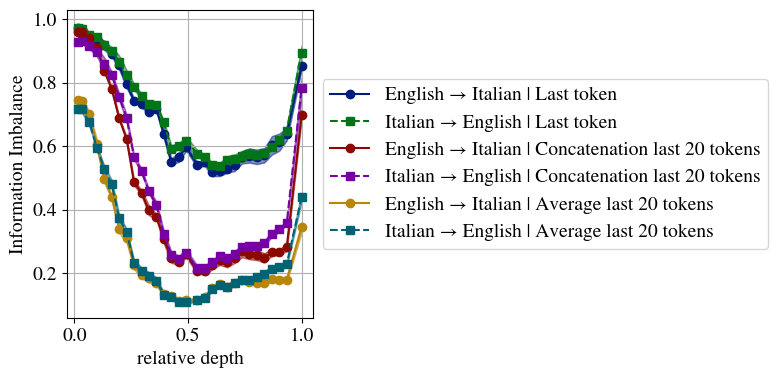

In [ ]:
for language_pair_id, (languageA, languageB) in enumerate(language_pairs):
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    seen_labels = set()
    for avg_tokens in avg_tokens_list:
        for n_tokens in n_tokens_list:
            if n_tokens == 1 and avg_tokens == 1:
                continue
            cond_id = cond_to_id[(avg_tokens, n_tokens)]

            mean_ii, std_ii = load_ii_curves(
                base="../results/santiago/",
                batch_shuffle=batch_shuffle,
                model=model,
                aux_A=aux_A,
                aux_B=aux_B,
                n_files=n_files,
                min_token_length=_min_token_length(model, languageA, languageB),
                languageA=languageA,
                languageB=languageB,
                mask=mask,
                k=k_II,
                Nbits=Nbits,
                seeds=seeds_II,
                n_tokens=n_tokens,
                avg_tokens=avg_tokens,
            )

            ls_A = linestyle_for_language(languageA, _linestyles)
            ls_B = linestyle_for_language(languageB, _linestyles)

            # One distinct color per condition + direction (English->Other / Other->English).
            color_idx_eo = (2 * cond_id + 0) % len(colors)  # English -> Other
            color_idx_oe = (2 * cond_id + 1) % len(colors)  # Other -> English
            color_eo = colors[color_idx_eo]
            color_oe = colors[color_idx_oe]

            # Markers encode direction relative to English (keep consistent across plots).
            marker_eo = "o"
            marker_oe = "s"

            # Map colors/markers to AB (A->B) and BA (B->A) based on where English sits.
            if languageA == "english":
                color_AB, color_BA = color_eo, color_oe
                marker_AB, marker_BA = marker_eo, marker_oe
            elif languageB == "english":
                color_AB, color_BA = color_oe, color_eo
                marker_AB, marker_BA = marker_oe, marker_eo
            else:
                # Fallback: keep original directional markers/colors if English is not present.
                color_AB = colors[(2 * cond_id + 0) % len(colors)]
                color_BA = colors[(2 * cond_id + 1) % len(colors)]
                marker_AB, marker_BA = "o", "s"

            if n_tokens == 1:
                cond_label = "Last token"
            elif avg_tokens == 0:
                cond_label = "Concatenation last 20 tokens"
            else:
                cond_label = "Average last 20 tokens"

            label_AB = f"{languageA.capitalize()} → {languageB.capitalize()} | {cond_label}"
            label_BA = f"{languageB.capitalize()} → {languageA.capitalize()} | {cond_label}"
            

            # A -> B (AB)
            use_label = label_AB if label_AB not in seen_labels else None
            ax.plot(
                x,
                mean_ii[0],
                label=use_label,
                linestyle=ls_A,
                color=color_AB,
                marker=marker_AB,
            )
            if use_label:
                seen_labels.add(label_AB)

            ax.fill_between(
                x,
                mean_ii[0] - std_ii[0],
                mean_ii[0] + std_ii[0],
                alpha=0.5,
                color=color_AB,
            )

            # B -> A (BA)
            use_label = label_BA if label_BA not in seen_labels else None
            ax.plot(
                x,
                mean_ii[1],
                label=use_label,
                linestyle=ls_B,
                color=color_BA,
                marker=marker_BA,
            )
            if use_label:
                seen_labels.add(label_BA)

            ax.fill_between(
                x,
                mean_ii[1] - std_ii[1],
                mean_ii[1] + std_ii[1],
                alpha=0.5,
                color=color_BA,
            )

    ax.set_xlabel("relative depth")
    ax.set_ylabel("Information Imbalance")

    # Legend outside (right)
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    ax.grid()
    fig.savefig(fname=f'../results/figs/last-concat-avg_{languageB}.pdf', bbox_inches='tight')
    plt.show()

In [4]:
# # -----------------------
# # Averaged across language pairs
# # -----------------------
# fig, ax = plt.subplots(1, 1, figsize=(6, 4))

# seen_labels = set()

# for avg_tokens in avg_tokens_list:
#     for n_tokens in n_tokens_list:
#         if n_tokens == 1 and avg_tokens == 1:
#             continue

#         cond_id = cond_to_id[(avg_tokens, n_tokens)]
#         ls = _linestyles[cond_id % len(_linestyles)]

#         means_AB = []
#         means_BA = []

#         for languageA, languageB in language_pairs:
#             mean_ii, std_ii = load_ii_curves(
#                 base="../results/santiago/",
#                 batch_shuffle=batch_shuffle,
#                 model=model,
#                 aux_A=aux_A,
#                 aux_B=aux_B,
#                 n_files=n_files,
#                 min_token_length=min_token_length,
#                 languageA=languageA,
#                 languageB=languageB,
#                 mask=mask,
#                 k=k_II,
#                 Nbits=Nbits,
#                 seeds=seeds_II,
#                 n_tokens=n_tokens,
#                 avg_tokens=avg_tokens,
#             )

#             means_AB.append(mean_ii[0])
#             means_BA.append(mean_ii[1])

#         means_AB = np.stack(means_AB, axis=0)
#         means_BA = np.stack(means_BA, axis=0)

#         mean_AB = means_AB.mean(axis=0)
#         mean_BA = means_BA.mean(axis=0)
#         std_AB = means_AB.std(axis=0)
#         std_BA = means_BA.std(axis=0)

#         color_AB = colors[(2 * cond_id + 0) % len(colors)]
#         color_BA = colors[(2 * cond_id + 1) % len(colors)]

#         if n_tokens == 1:
#             cond_label = "Last token"
#         elif avg_tokens == 0:
#             cond_label = "Concatenation last 20 tokens"
#         else:
#             cond_label = "Average last 20 tokens"

#         label_AB = f"English → Other | {cond_label}"
#         label_BA = f"Other → English | {cond_label}"

#         use_label = label_AB if label_AB not in seen_labels else None
#         ax.plot(
#             x,
#             mean_AB,
#             label=use_label,
#             linestyle=ls,
#             color=color_AB,
#             marker="o",
#         )
#         if use_label:
#             seen_labels.add(label_AB)

#         ax.fill_between(
#             x,
#             mean_AB - std_AB,
#             mean_AB + std_AB,
#             alpha=0.35,
#             color=color_AB,
#         )

#         use_label = label_BA if label_BA not in seen_labels else None
#         ax.plot(
#             x,
#             mean_BA,
#             label=use_label,
#             linestyle=ls,
#             color=color_BA,
#             marker="s",
#         )
#         if use_label:
#             seen_labels.add(label_BA)

#         ax.fill_between(
#             x,
#             mean_BA - std_BA,
#             mean_BA + std_BA,
#             alpha=0.35,
#             color=color_BA,
#         )

# ax.set_xlabel("relative depth")
# ax.set_ylabel("Information Imbalance")

# # Legend above
# ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
# # fig.savefig(fname="../results/figs/fig1_avg_pairs.pdf", bbox_inches="tight")
# plt.show()
